# Assignment 2 — Tree Calibration

Sources: `Lectures/2026_fall_BME/04_Tree/Tree.ipynb` and `Binomial_tree_coding.ipynb`.

**Task:** Calibrate the up-step of a balanced binomial tree to a given European call price using a numerical root solver. Compare step counts with flat-rate discounting, calibrate one-step contracts at different strikes and expiries, and plot the results.

**Solution:** `calibrate` in `tree_calibration.py`, using `scipy.optimize.brentq`.

$$\Delta t=T/n,\qquad D=e^{-r\Delta t},\qquad m=1/D,$$
$$p_u=p_d=\tfrac12,\qquad d=2m-u,$$
$$V_{i,j}=\tfrac12D(V_{i+1,j}+V_{i+1,j+1}),\qquad V_{n,j}=\max(S_{n,j}-K,0).$$

Calibration equation:

$$C_{\mathrm{tree}}(u)-C_{\mathrm{observed}}=0,\qquad m<u<2m.$$

Search parameter: $u=m(1+a)$, $d=m(1-a)$, $0<a<1$. Total discount factor: $D^n=e^{-rT}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from tree_calibration import (calibrate, balanced_call_price, calcBalancedDownStep,
                              create_spot_tree, create_discounted_price_tree)


def example_observed_call(spot, K, expiry, rate, sigma):
    # Synthetic market observation from the lecture's Black–Scholes formula.
    d1 = (np.log(spot/K)+(rate+.5*sigma**2)*expiry)/(sigma*np.sqrt(expiry))
    d2 = d1-sigma*np.sqrt(expiry)
    return spot*norm.cdf(d1)-K*np.exp(-rate*expiry)*norm.cdf(d2)


## Same contract with different step counts

$S_0=K=100$, $T=1$, $r=0.05$. Synthetic observed price from Black–Scholes with $\sigma=0.20$.

$n\in\{1,2,4,8,16,32,64,128\}$.

Fixed observed call price: 10.450583572186
steps        up        down     DF/step    DF/expiry      repriced       residual
    1    1.219728    0.882814    0.951229    0.951229   10.450583572   +1.42e-14
    2    1.175628    0.875002    0.975310    0.951229   10.450583572   +1.95e-14
    4    1.113772    0.911385    0.987578    0.951229   10.450583572   -7.11e-15
    8    1.076632    0.935907    0.993769    0.951229   10.450583572   -3.55e-15
   16    1.052727    0.953532    0.996880    0.951229   10.450583572   +1.28e-13
   32    1.036700    0.966428    0.998439    0.951229   10.450583572   -3.91e-14
   64    1.025707    0.975856    0.999219    0.951229   10.450583572   -1.17e-13
  128    1.018072    0.982709    0.999609    0.951229   10.450583572   -1.49e-13


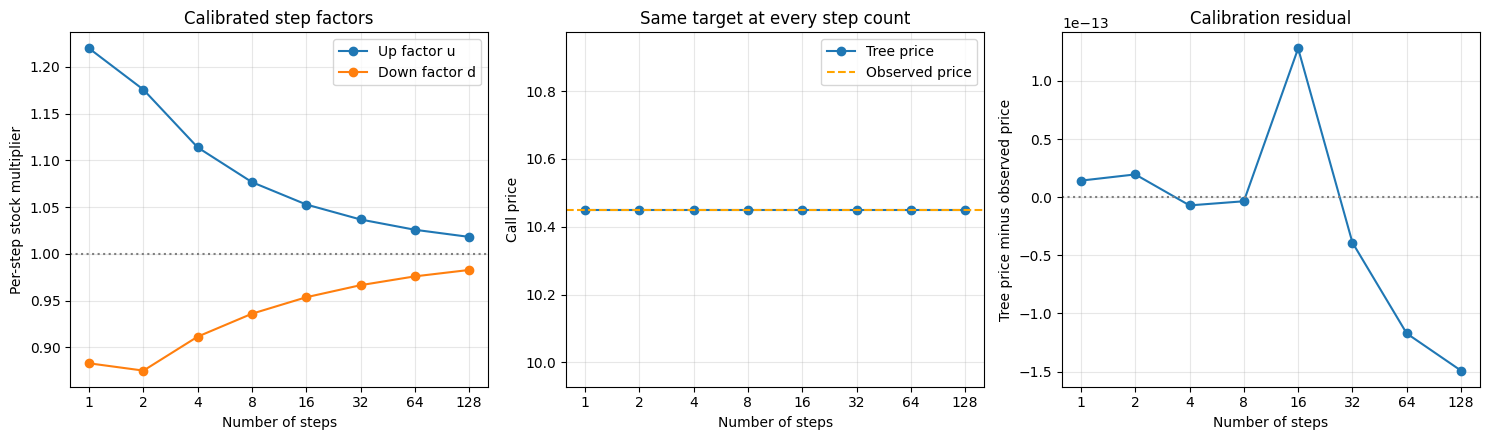

In [2]:
spot, K, expiry, rate = 100., 100., 1., .05
observed = example_observed_call(spot, K, expiry, rate, .2)
step_counts = np.array([1, 2, 4, 8, 16, 32, 64, 128])
rows = []
print(f'Fixed observed call price: {observed:.12f}')
print('steps        up        down     DF/step    DF/expiry      repriced       residual')
for n in step_counts:
    up = calibrate(observed, int(n), K, expiry, rate, spot)
    df = np.exp(-rate*expiry/n)
    down = calcBalancedDownStep(up, df)
    price = balanced_call_price(spot, up, int(n), K, expiry, rate)
    np.testing.assert_allclose(price, observed, rtol=0, atol=1e-10)
    np.testing.assert_allclose(df**n, np.exp(-rate*expiry), rtol=1e-12)
    np.testing.assert_allclose((1/df-down)/(up-down), .5, rtol=1e-12)
    rows.append((n, up, down, price, price-observed))
    print(f'{n:5d}   {up:9.6f}   {down:9.6f}   {df:9.6f}   {df**n:9.6f}   {price:12.9f}   {price-observed:+.2e}')
rows = np.array(rows)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].plot(rows[:, 0], rows[:, 1], 'o-', label='Up factor u')
axes[0].plot(rows[:, 0], rows[:, 2], 'o-', label='Down factor d')
axes[0].axhline(1, color='gray', linestyle=':')
axes[0].set_ylabel('Per-step stock multiplier')
axes[0].set_title('Calibrated step factors')
axes[0].legend()
axes[1].plot(rows[:, 0], rows[:, 3], 'o-', label='Tree price')
axes[1].axhline(observed, color='orange', linestyle='--', label='Observed price')
axes[1].set_ylabel('Call price')
axes[1].set_title('Same target at every step count')
axes[1].set_ylim(.95*observed, 1.05*observed)
axes[1].ticklabel_format(axis='y', style='plain', useOffset=False)
axes[1].legend()
axes[2].plot(rows[:, 0], rows[:, 4], 'o-')
axes[2].axhline(0, color='gray', linestyle=':')
axes[2].set_ylabel('Tree price minus observed price')
axes[2].set_title('Calibration residual')
axes[2].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
for ax in axes:
    ax.set_xscale('log', base=2)
    ax.set_xticks(step_counts, labels=step_counts)
    ax.set_xlabel('Number of steps')
    ax.grid(True, alpha=.3)
fig.tight_layout()
plt.show()

## One-step contracts with different strikes and expiries

$S_0=100$, $r=0.05$, $K\in\{80,90,100,110,120\}$, $T\in\{0.25,1,2\}$.

Synthetic observed prices from Black–Scholes with $\sigma=0.25$. Each contract is calibrated separately.

One-step reference solution:

$$u=\frac{K+2Ce^{rT}}{S_0}.$$

expiry  strike    observed        up        down      repriced      residual
  0.25      80  21.1212244   1.227738   0.797419   21.1212244 -7.11e-15
  0.25      90  12.2100426   1.147273   0.877884   12.2100426 +8.88e-15
  0.25     100   5.5984002   1.113376   0.911781    5.5984002 -7.99e-15
  0.25     110   1.9805064   1.140108   0.885049    1.9805064 +2.89e-15
  0.25     120   0.5455312   1.211048   0.814109    0.5455312 +8.88e-16
  1.00      80  25.4125120   1.334309   0.768233   25.4125120 -7.11e-15
  1.00      90  18.1407630   1.281417   0.821125   18.1407630 -1.07e-14
  1.00     100  12.3359989   1.259370   0.843173   12.3359989 +0.00e+00
  1.00     110   8.0263847   1.268758   0.833784    8.0263847 +1.78e-15
  1.00     120   5.0254135   1.305661   0.796881    5.0254135 -3.55e-15
  2.00      80  30.5291646   1.474799   0.735543   30.5291646 +0.00e+00
  2.00      90  24.0697053   1.432023   0.778319   24.0697053 +7.11e-15
  2.00     100  18.6470758   1.412164   0.798178   18.64707

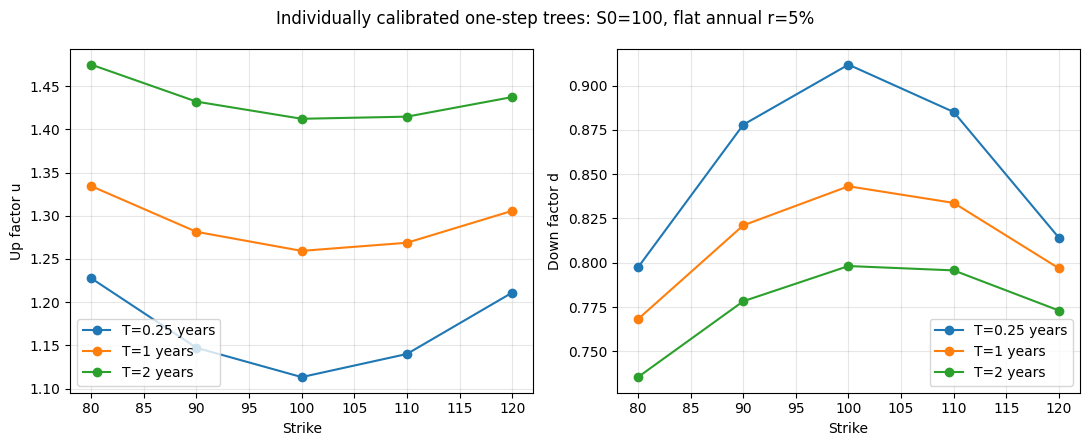

In [3]:
strikes = np.array([80., 90., 100., 110., 120.])
expiries = [.25, 1., 2.]
one_step_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
print('expiry  strike    observed        up        down      repriced      residual')
for T in expiries:
    ups, downs = [], []
    df = np.exp(-rate*T)
    for strike in strikes:
        target = example_observed_call(spot, strike, T, rate, .25)
        up = calibrate(target, 1, strike, T, rate, spot)
        down = calcBalancedDownStep(up, df)
        price = balanced_call_price(spot, up, 1, strike, T, rate)
        expected_up = (strike+2*target/df)/spot
        np.testing.assert_allclose(up, expected_up, rtol=0, atol=1e-11)
        np.testing.assert_allclose(price, target, rtol=0, atol=1e-10)
        assert spot*down < strike < spot*up
        ups.append(up)
        downs.append(down)
        one_step_rows.append((T, strike, target, up, down, price))
        print(f'{T:6.2f} {strike:7.0f} {target:11.7f} {up:10.6f} {down:10.6f} {price:12.7f} {price-target:+.2e}')
    axes[0].plot(strikes, ups, 'o-', label=f'T={T:g} years')
    axes[1].plot(strikes, downs, 'o-', label=f'T={T:g} years')
for ax, label in zip(axes, ['Up factor u', 'Down factor d']):
    ax.set_xlabel('Strike')
    ax.set_ylabel(label)
    ax.grid(True, alpha=.3)
    ax.legend()
fig.suptitle('Individually calibrated one-step trees: S0=100, flat annual r=5%')
fig.tight_layout()
plt.show()

## Calibrated one-step trees

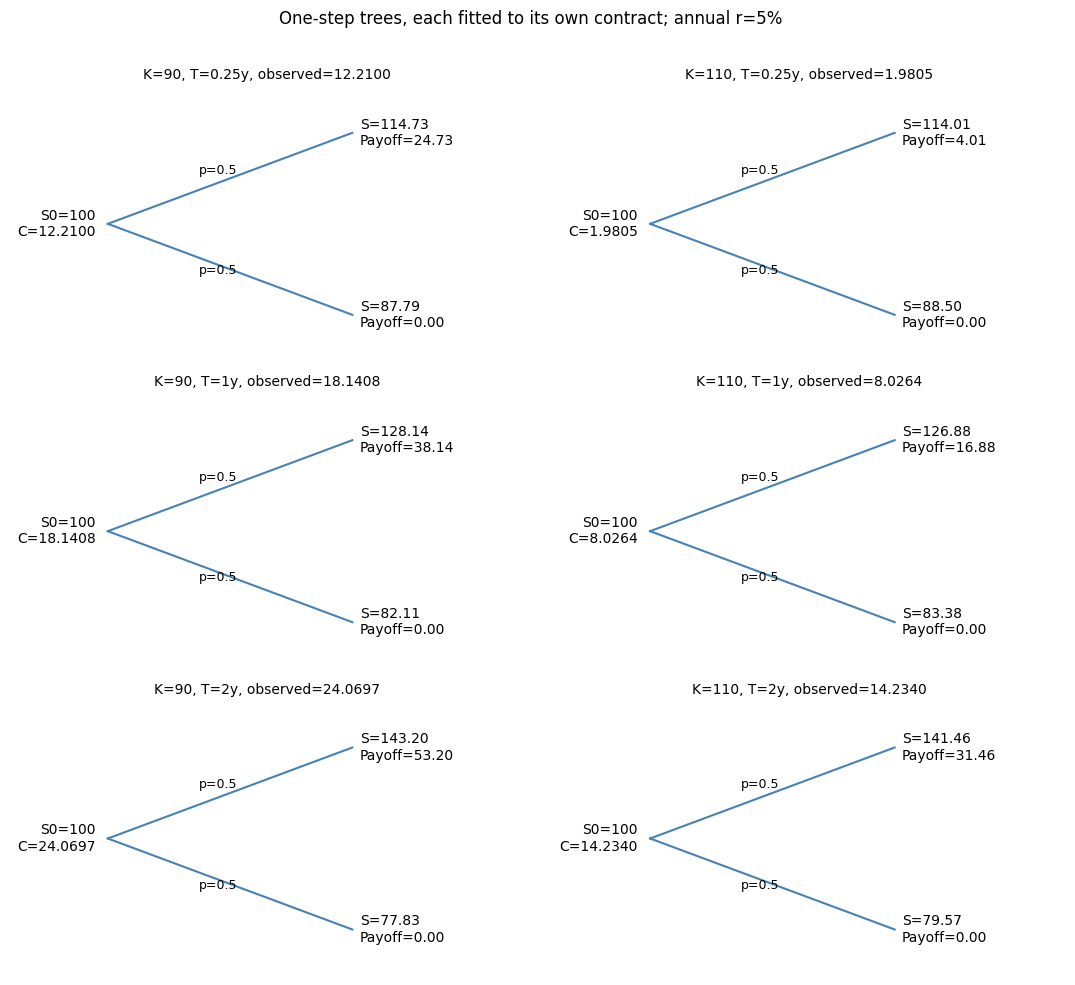

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for ax, row in zip(axes.flat, [row for row in one_step_rows if row[1] in [90., 110.]]):
    T, strike, target, up, down, price = row
    for y, factor in [(1, up), (-1, down)]:
        terminal_spot = spot*factor
        payoff = max(terminal_spot-strike, 0.)
        ax.plot([0, 1], [0, y], color='steelblue')
        ax.text(.45, .55*y, 'p=0.5', ha='center', fontsize=9)
        ax.text(1.03, y, f'S={terminal_spot:.2f}\nPayoff={payoff:.2f}',
                va='center', fontsize=10)
    ax.text(-.05, 0, f'S0={spot:.0f}\nC={price:.4f}', ha='right', va='center')
    ax.set_title(f'K={strike:.0f}, T={T:g}y, observed={target:.4f}', fontsize=10)
    ax.set_xlim(-.4, 1.7)
    ax.set_ylim(-1.5, 1.5)
    ax.axis('off')
fig.suptitle('One-step trees, each fitted to its own contract; annual r=5%')
fig.tight_layout(rect=(0, 0, 1, .97))
plt.show()